# Neural Network Example: Concrete Compressive Strength

**Background**<br>
Concrete strength is governed mainly by the *water-to-cement ratio* (Abrams' law) and the *curing age*. A lab database records mix proportions and the measured strength. We would like to build a model that predicts strength for a new mix without casting a single test cylinder, which saves lab time and material.

**Dataset** <br>
the *Concrete Compressive Strength* database (Yeh, 1998) consists of 1030 laboratory mixes with 8 recorded quantities
- cement
- slag
- fly ash
- water
- superplasticizer
- coarse & fine aggregate
- age
- 28-day strength in MPa

Yeh, I.-C. (1998), *Modeling of strength of high-performance concrete using artificial neural networks*, Cement and Concrete Research 28(12), 1797–1808. Distributed by the UCI Machine Learning Repository.

## The training loop

A training loop usually goes through the following five steps:

```python
optimizer.zero_grad()       # 1. forget the gradients from the previous step
y_hat  = model(x)           # 2. forward pass: make a prediction
loss   = loss_fn(y_hat, y)  # 3. measure how wrong we are
loss.backward()             # 4. backpropagation: compute gradients
optimizer.step()            # 5. update the weights a little
```

Only three things change between architectures: 
- the data
- the model (`nn.Module`) 
- the loss function

In [1]:
import torch                        # PyTorch: tensors + autograd
import torch.nn as nn               # neural-network building blocks (layers, losses)
import pandas as pd                 # read the CSV, inspect the data
import matplotlib.pyplot as plt     # plotting

torch.manual_seed(355)              # reproducibility: same "random" numbers every run
print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.1


## Multiple Layer Perceptron

### 1. Load the dataset
8 ingredient/curing inputs and 1 target (`strength`, MPa). Look at a few rows first — always inspect real data before modeling.

In [2]:
df = pd.read_csv("Data/concrete.csv")   # 1030 real lab mixes (Yeh, 1998)
print(df.shape)          # 1030 rows (mixes) x 9 columns (8 inputs + strength)
df.head()

(1030, 9)


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:
df.describe().round(2)

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.35,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.40,968.00,779.50,28.00,34.44
75%,350.00,142.95,118.30,192.00,10.20,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


Notice the units are heterogeneous: cement in kg/m³ (~150–500), age in days (1–365), etc. Also note the strength spans roughly 2–83 MPa — real concrete covers everything from lean fills to high-strength columns.

### 2. To tensors, standardize, and split
Neural networks train best when every input is on a similar scale (z-scores). We reserve 20% of mixes as a test set that the model never trains on, like a final exam.

In [4]:
X_raw = torch.tensor(df.drop(columns="strength").values, dtype=torch.float32)  # 8 inputs -> tensor (1030, 8)
y = torch.tensor(df["strength"].values, dtype=torch.float32).unsqueeze(1)      # target -> (1030, 1) to match model output

perm = torch.randperm(len(X_raw))              # SHUFFLE first: the database file is
X_raw, y = X_raw[perm], y[perm]                # sorted by cement content
X = (X_raw - X_raw.mean(0)) / X_raw.std(0)     # z-score each column (mean 0, std 1)
split = int(0.8 * len(X))                      # boundary for the 80/20 split
X_train, X_test = X[:split], X[split:]         # slice: 80% train, 20% test
y_train, y_test = y[:split], y[split:]
print("train:", X_train.shape, " test:", X_test.shape)

train: torch.Size([824, 8])  test: torch.Size([206, 8])


### 3. Build the NN model

`nn.Sequential` stacks layers left to right:
-`Linear` does `w·x + b`, 
- `ReLU` adds non-linearity (without it, stacked layers collapse into one linear map). 

The shape changes along the sequencial process: 8 -> 64 -> 64 -> 1.

In [5]:
# an NN with one input layer, two hidden layers, and one output layer
model = nn.Sequential(                 # runs layers in order, like a pipeline
    nn.Linear(8, 64), nn.ReLU(),       # 8 inputs -> 64 hidden units, then max(x, 0)
    nn.Linear(64, 64), nn.ReLU(),      # 64 -> 64
    nn.Linear(64, 1),                  # 64 -> 1 predicted strength (MPa)
)
loss_fn   = nn.MSELoss()                              # squared error (regression)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # lr is the learning rate, which needs to be chosen appropriately

### 4. Train the model
An *epoch* is one full pass over the training data.

In [6]:
for epoch in range(2000):                  # full-batch training: all 824 mixes at once
    optimizer.zero_grad()                  # 1. forget the gradients from the previous step
    y_hat = model(X_train)                 # 2. forward pass: predict strengths
    loss  = loss_fn(y_hat, y_train)        # 3. measure how wrong we are (MSE)
    loss.backward()                        # 4. backprop: dLoss/dWeight for EVERY weight (autograd)
    optimizer.step()                       # 5. update all weights a small step downhill
    if (epoch + 1) % 100 == 0:             # print progress every 100 epochs
        print(f"epoch {epoch+1:4d} | train MSE = {loss.item():.2f} MPa^2")

epoch  100 | train MSE = 412.08 MPa^2
epoch  200 | train MSE = 173.36 MPa^2
epoch  300 | train MSE = 144.93 MPa^2
epoch  400 | train MSE = 124.84 MPa^2
epoch  500 | train MSE = 104.78 MPa^2
epoch  600 | train MSE = 80.12 MPa^2
epoch  700 | train MSE = 50.24 MPa^2
epoch  800 | train MSE = 36.16 MPa^2
epoch  900 | train MSE = 29.42 MPa^2
epoch 1000 | train MSE = 25.23 MPa^2
epoch 1100 | train MSE = 21.87 MPa^2
epoch 1200 | train MSE = 19.06 MPa^2
epoch 1300 | train MSE = 16.74 MPa^2
epoch 1400 | train MSE = 14.87 MPa^2
epoch 1500 | train MSE = 13.34 MPa^2
epoch 1600 | train MSE = 12.17 MPa^2
epoch 1700 | train MSE = 11.26 MPa^2
epoch 1800 | train MSE = 10.50 MPa^2
epoch 1900 | train MSE = 9.90 MPa^2
epoch 2000 | train MSE = 9.35 MPa^2


### 5. Evaluate on the unseen test set

$$
    R^2=1-\frac{\sum (y - \hat y)^2}{\sum (y - \bar y)^2}
$$


Test R^2 = 0.912


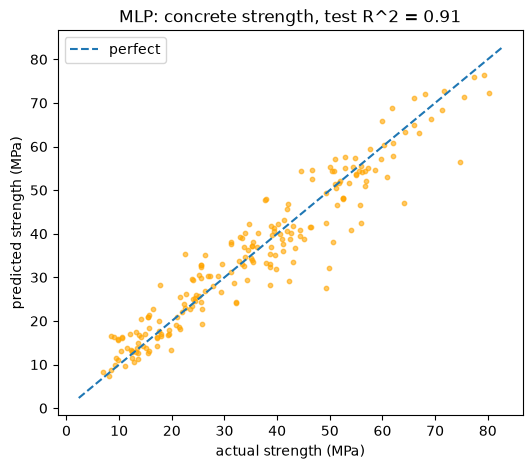

In [7]:
model.eval()                             # evaluation mode
with torch.no_grad():                    # no gradients needed for evaluation
    y_pred = model(X_test)               # predictions on the unseen test mixes
# R^2 = 1 - (sum of squared errors) / (variance of y); 1.0 = perfect, 0 = no better than the mean
r2 = 1 - ((y_test - y_pred)**2).sum() / ((y_test - y_test.mean())**2).sum()
print(f"Test R^2 = {r2.item():.3f}")

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, s=10, color='orange', alpha=0.6)   # one dot per test mix
plt.plot([y.min(), y.max()], [y.min(), y.max()], "--", label="perfect")  # y = x reference line
plt.xlabel("actual strength (MPa)")
plt.ylabel("predicted strength (MPa)")
plt.title(f"MLP: concrete strength, test R^2 = {r2.item():.2f}")
plt.legend(); plt.show()


**Exercises**
1. Points far below the red line are mixes the model **over-predicted**. Which input might explain them? 
2. Which input matters most? Train the model with one column removed at a time and watch $R^2$.
3. Increase the network to 8 → 128 → 128 → 1. Does $R^2$ improve on the **test** set, or only on the training data?